# 3. Tahmin modeli

**Bu defter.** Tahmin modeli nasıl kuruldu ve ne kadar iyi? Önce tahmin modelinin girdisini, eğitimini ve görmediği
ilanlardaki hatasını kuruyoruz. Sonra onu iki basit medyan kuralıyla ve başka bir algoritmayla (CatBoost) aynı
katlarda karşılaştırıyoruz. Ardından tahmin modelinin neyi kullandığına bakıyoruz: marka bir şey katıyor mu, bir
öznitelik çıkınca hata ne kadar büyüyor, tahmin modelinde olmayan dört ham kolon eklense ne olurdu. Son bölüm
servis edilen son tahmin modeline ayrılmış.

| bölüm | soru |
|---|---|
| Kurulum ve veri | Hangi ilanlarla çalışıyoruz, ağır adımlar nasıl saklanıyor? |
| 1. Tahmin modeli | Neye bakıyor, nasıl eğitiliyor, görmediği ilanlarda ne kadar yanılıyor? |
| 2. Tabanlar ve karşılaştırma | Araç modeli + yıl medyanına ve CatBoost'a göre nerede? |
| 3. Marka ablasyonu | Seri ve araç modeli bilinince marka bir şey katıyor mu? |
| 4. Hangi öznitelik ne kadar taşıyor | Bir öznitelik çıkınca hata ne kadar büyüyor; dört ham kolon eklenseydi? |
| 5. Son tahmin modeli | Servis edilen tahmin modeli nasıl eğitiliyor? |
| Özet | Defterin gösterdikleri |
| Başlık sayıları | Defterin sayıları, hesaplandıkları bölümle, tek tabloda |

Defter veritabanını yalnız okur. Yazdığı tek yer kendi önbelleği (`data/cache/`, Kurulum ve veri). İlan numaraları
(`ad_id`) hiçbir çıktıda gösterilmez; satıcıların yazdığı metinler bu defterde hiç okunmaz.
Sonuçların sayıları metinde yazılmaz, hücre çıktılarında görünür; metin neye bakılacağını ve ne görüldüğünü söyler.

> **Terimler** (araç modeli, tahmin modeli, ilan, öznitelik ve model yılı 1. defterdeki, log fiyat ve kat dışı 2.
> defterdeki anlamıyla)
>
> - **kat**: ilanlar beş kata bölünür. Bir katın ilanları, öteki dört katta eğitilen tahmin modeliyle tahmin edilir;
>   bu **kat dışı** tahmindir. Bir katın **eğitim kısmı** öteki dört kat, **doğrulama kısmı** katın kendisi.
> - **hata ölçüleri**, hepsi ₺ fiyat üzerinde (log tahmin exp(tahmin) − 1 ile ₺'ye çevrilir): **MAE** ortalama mutlak
>   hata (₺); **MedAE** medyan mutlak hata (₺), tipik ilanın hatası; **RMSE** hata karelerinin ortalamasının kökü
>   (₺), büyük hataları ağır tartar; **MAPE** gerçek fiyatın yüzdesi olarak ortalama mutlak hata; **R²** fiyatın
>   ilanlar arasındaki değişiminin açıklanan payı.
> - **taban**: tahmin modeliyle karşılaştırılan basit kural (2. bölüm).

## Kurulum ve veri

İlk hücre kütüphaneleri ve `lib` klasöründen bu defterin modüllerini yükler: `data` (veriyi okuma ve türetilen
kolonlar; 1. defter), `folds` (ortak beş kat; 2. defter), `model` (kat matrisleri, LightGBM ve CatBoost koşumları,
hata ölçüleri, medyan tabanı) ve `cache` (önbellek).
Her modülün ne yaptığı kullanıldığı yerde anlatılıyor.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lib import cache, data, folds, model

pd.set_option("display.max_colwidth", None)   # uzun etiketler tablolarda kesilmesin

Defter 1. defterin ilan tablosuyla çalışır: her ilanın en son taramadaki satırı, tahmin modelinin kolonları
`data.add_features` ile eklenmiş. Satırların nasıl seçildiği ve kolonların nasıl türetildiği 1. defterde.

In [2]:
listings = data.add_features(data.load_rows())
print("İlanlar (satır, kolon):", listings.shape)

İlanlar (satır, kolon): (29988, 133)


**Önbellek.** Tahmin modelini beş katta eğitmek bu makinede onlarca saniye sürüyor ve defter bunu otuzdan fazla kez
yapıyor. Bu ağır adımlar `cache.load_or_run(fonksiyon, argümanlar ...)` ile çağrılıyor: `data/cache/` altında aynı
anahtarlı bir kayıt varsa okunur; yoksa fonksiyon koşar ve sonucu kaydedilir. Anahtar şunları kapsar:

- veritabanı dosyasının (`data/cars.duckdb`) parmak izi (sha256);
- fonksiyonun lib modülünün ve onun import ettiği lib modüllerinin metni (ayarlar bu modüllerde);
- temel paketlerin sürümleri (numpy, pandas, scikit-learn, LightGBM, CatBoost ...);
- fonksiyonun adı ve argümanlarının içeriği: tablonun her değeri, katlar, çıkarılan ya da eklenen kolonlar.

Bunlardan biri değişince adım yeniden koşar; eski bir kayıt sessizce okunmaz. Kayıt yoksa defter baştan sona uzun
sürer, kayıtlar varsa birkaç saniye. Veritabanının bu koşumdaki parmak izinin başı:

In [3]:
print("Veritabanı:", cache.db_digest()[:16])

Veritabanı: 444123b1f1a9f7e5


## 1. Tahmin modeli

**Soru.** Tahmin modeli neye bakıyor, nasıl eğitiliyor ve görmediği ilanlarda ne kadar yanılıyor?

### 1.1 Girdi, hedef ve katlar

Girdi 1. defterdeki öznitelikler (`data.FEATURES`): araç modeli ve seri adı (metin), dokuz kategorik ve on dört
sayısal kolon. Hedef log fiyat, log(1 + fiyat) (2. defter, 3. bölüm). Katlar `folds.make_folds` ile kuruluyor:
karıştırılmış beş kat, tohum 42; 2. defterin hedonik regresyonu da aynı fonksiyonu kullanıyor. Katlar satır sırasına
bağlı; `data.load_rows` ilanları `ad_id` sırasıyla verdiği için her koşumda aynı katlar çıkar.

In [4]:
model_table = listings[data.FEATURES + ["price"]]
price = model_table["price"].to_numpy(dtype=float)
cv_folds = folds.make_folds(len(model_table))
print("Öznitelik:", len(data.FEATURES), "| ilan:", len(model_table))

pd.Series([len(valid) for _, valid in cv_folds], index=range(1, folds.N_FOLDS + 1)).rename_axis("kat").rename(
    "doğrulama kısmındaki ilan").to_frame().T

Öznitelik: 25 | ilan: 29988


kat,1,2,3,4,5
doğrulama kısmındaki ilan,5998,5998,5998,5997,5997


### 1.2 Bir katın matrisi

`model.fold_matrices` bir katın eğitim ve doğrulama matrisini kurar. Her adım yalnız eğitim kısmından öğrenilir,
doğrulama kısmına yalnız uygulanır; böylece doğrulama ilanlarının hiçbir bilgisi eğitime sızmaz.

- **Kategorik kolonlar** tamsayı kodlara çevrilir: değerler eğitim kısmında ilk görüldükleri sırayla 0, 1, 2 ...;
  eğitim kısmında hiç görülmemiş bir değer −1 alır. LightGBM bu kolonları kategorik olarak işler.
- **Sayısal kolonlar** olduğu gibi girer; boş değer boş kalır, LightGBM boşluğu kendisi işler.
- **Araç modeli ve seri adı** sayılara çevrilir: önce karakter TF-IDF'i (kelime içindeki 3–5 harflik parçaların
  ağırlıkları; en az 5 ilanda geçen parçalar), sonra SVD ile TF-IDF'in çok sayıdaki kolonundan araç modeli için 150,
  seri için 20 kolona indirgeme. Araç modelinin yüzlerce değeri var ve çoğu az ilanlı; ad parçaları sayesinde az
  ilanlı bir araç modeli, adı benzeyen araç modellerinden bilgi ödünç alabiliyor ("320i" ile "320d" gibi). TF-IDF ilan
  açıklamasına değil, yalnız bu iki ada uygulanıyor; satıcının yazdığı metin tahmin modeline hiçbir biçimde girmez.

In [5]:
print("TF-IDF ayarı:", model.TFIDF)
print("SVD boyutu:", model.TEXT_SVD)

X_train, X_valid, categorical = model.fold_matrices(model_table, *cv_folds[0])
print("1. katın matrisleri (satır, kolon): eğitim", X_train.shape, "| doğrulama", X_valid.shape)

TF-IDF ayarı: {'analyzer': 'char_wb', 'ngram_range': (3, 5), 'min_df': 5}
SVD boyutu: {'model': 150, 'series': 20}


1. katın matrisleri (satır, kolon): eğitim (23990, 193) | doğrulama (5998, 193)


Matrisin kolonları türlerine göre; aynı sayım 5. bölümde son tahmin modelinin matrisi için de yapılıyor:

In [6]:
KIND_TR = {"categorical": "kategorik", "numeric": "sayısal", "model": "araç modeli adı (SVD)",
           "series": "seri adı (SVD)"}   # yalnız gösterim için


def column_kinds(columns, categorical):
    """Matris kolonlarının türü: kategorik, sayısal ya da hangi adın SVD kolonu. Döndürür: tür başına kolon sayısı."""
    kinds = ["categorical" if c in categorical else c.split("_")[0] if c.startswith(("model_", "series_"))
             else "numeric" for c in columns]
    return pd.Series(kinds).value_counts().reindex(list(KIND_TR))


column_kinds(X_train.columns, categorical).rename(KIND_TR).rename_axis("kolon türü").rename("kolon").to_frame()

,kolon
kolon türü,
kategorik,9
sayısal,14
araç modeli adı (SVD),150
seri adı (SVD),20


### 1.3 LightGBM ve ayarları

Tahmin modeli LightGBM: art arda eklenen karar ağaçları, her yeni ağaç öncekilerin bıraktığı hatayı küçültür.
Ayarlar `model` modülünde adlı sabitler; burada hepsi açıkça:

In [7]:
LGB_NOTES = {"n_estimators": "ağaç sayısının üst sınırı; erken durdurma çoğunlukla daha önce durur",
             "learning_rate": "her ağacın katkısı bu oranla küçültülür",
             "num_leaves": "bir ağacın en çok yaprak sayısı",
             "min_child_samples": "bir yaprakta en az kaç ilan olmalı",
             "random_state": "tohum",
             "verbose": "LightGBM'in kendi iletileri kapalı",
             "deterministic": "aynı girdi ve ayarla aynı ağaçlar",
             "force_row_wise": "deterministic'in çok iş parçacığında da tutması için",
             "n_jobs": "iş parçacığı sayısı"}

pd.DataFrame({"value": pd.Series(model.LGB_PARAMS).astype(str), "note": pd.Series(LGB_NOTES)}).rename_axis(
    "ayar").rename(columns={"value": "değer", "note": "ne"})

,değer,ne
ayar,,
n_estimators,900,ağaç sayısının üst sınırı; erken durdurma çoğunlukla daha önce durur
learning_rate,0.05,her ağacın katkısı bu oranla küçültülür
num_leaves,128,bir ağacın en çok yaprak sayısı
min_child_samples,20,bir yaprakta en az kaç ilan olmalı
random_state,42,tohum
verbose,-1,LightGBM'in kendi iletileri kapalı
deterministic,True,aynı girdi ve ayarla aynı ağaçlar
force_row_wise,True,deterministic'in çok iş parçacığında da tutması için
n_jobs,16,iş parçacığı sayısı


**Erken durdurma.** Her katta ağaçlar yalnız eğitim kısmında büyür; doğrulama kısmının hatası her turdan sonra
ölçülür ve bu hata art arda 40 tur iyileşmezse eğitim durur. Tahmin, hatanın en düşük olduğu turdaki ağaç sayısıyla
yapılır. Bunun bir bedeli var: durma noktasını puanlanan katın kendisi seçiyor, bu yüzden kat dışı hata biraz iyimser
olabilir. Ağaçların kendisi doğrulama ilanlarını görmez. Son tahmin modeli bu yüzden erken durdurmayla değil, katların
seçtiği ağaç sayılarının medyanıyla eğitiliyor (5. bölüm).

İş parçacığı sayısı LightGBM'in sonucunu değiştirmiyor (`tests/lib/test_model.py`); yine de sabit, çünkü son tahmin
modelinin metnine yazılıyor.

In [8]:
print("Erken durdurma:", model.EARLY_STOP, "tur")

Erken durdurma: 40 tur


### 1.4 Kat dışı koşum

`model.oof_lightgbm` beş katın her birinde matrisleri kurar, LightGBM'i eğitim kısmında erken durdurmayla eğitir ve
doğrulama kısmını tahmin eder. Döndürür: her ilanın kat dışı log tahmini ve her katta seçilen ağaç sayısı. Bütün
öznitelikli bu koşum defterin **temel koşumu**; 3. ve 4. bölümdeki her koşum ona göre okunuyor. Önbellekten:

In [9]:
base = cache.load_or_run(model.oof_lightgbm, model_table, cv_folds)
base_price = np.expm1(base["pred_log"])
print("Erken durdurmanın seçtiği ağaç sayısı, kat kat:", base["trees"])

Erken durdurmanın seçtiği ağaç sayısı, kat kat: [274, 258, 212, 212, 307]


Beş hata ölçüsü. Aynı tablo aşağıda her karşılaştırmada kullanılıyor: ₺ ölçüleri tam sayıya, MAPE iki, R² dört haneye
yuvarlanır.

In [10]:
METRIC_TR = {"mae": "MAE (₺)", "medae": "MedAE (₺)", "rmse": "RMSE (₺)", "mape": "MAPE (%)", "r2": "R²"}


def metric_table(predictions):
    """Her ₺ tahmini için beş hata ölçüsü (model.price_metrics), gösterildiği gibi yuvarlanmış; tahmin başına satır."""
    table = pd.DataFrame({name: model.price_metrics(price, pred) for name, pred in predictions.items()}).T
    rounded = table.round({"mae": 0, "medae": 0, "rmse": 0, "mape": 2, "r2": 4})
    return rounded.astype({"mae": int, "medae": int, "rmse": int})


base_metrics = model.price_metrics(price, base_price)
metric_table({"lightgbm": base_price}).rename(index={"lightgbm": "tahmin modeli (LightGBM)"}, columns=METRIC_TR)

,MAE (₺),MedAE (₺),RMSE (₺),MAPE (%),R²
tahmin modeli (LightGBM),109776,75320,176225,6.49,0.9745


**Ne görüyoruz.** Tipik ilanın hatası (MedAE) ortalama hatadan (MAE) belirgin küçük, RMSE ise MAE'den de büyük:
hataların çoğu küçük, bir kısmı büyük, ve RMSE büyükleri ağır tartıyor. Hata fiyatın yüzdesi olarak tek haneli; R²,
₺ fiyatın ilanlar arasındaki değişiminin neredeyse tamamının açıklandığını söylüyor. Erken durdurma katlar arasında
farklı turlarda duruyor; son tahmin modeli bu sayıların medyanıyla eğitiliyor (5. bölüm).

## 2. Tabanlar ve karşılaştırma

**Soru.** Tahmin modeli, bir galericinin yapacağı basit bir hesaba ve başka bir algoritmaya göre nerede?

### 2.1 İki medyan tabanı

Taban, ilanın fiyatını benzer ilanların medyan fiyatıyla tahmin eden basit bir kural. İki taban var:

- **seri + yıl medyanı**: aynı seri ve aynı model yılı; kaba bir arama.
- **araç modeli + yıl medyanı**: aynı araç modeli ve aynı model yılı; bir galericinin emsal bakarken yaptığı.

`model.median_baseline` medyanları her katta yalnız eğitim kısmından hesaplar; katlar tahmin modelininkilerle aynı,
yani taban da kat dışı. Bir ilanın hücresi eğitim kısmında yoksa merdiven bir basamak iner: aynı araç modelinin
(serinin) bütün yılları, o da yoksa bütün eğitim ilanlarının medyanı. Fonksiyon her ilan için kullandığı basamağı da
verir.

In [11]:
series_pred, series_rung = model.median_baseline(listings["series"], listings["gb_year"], price, cv_folds)
dealer_pred, dealer_rung = model.median_baseline(listings["model"], listings["gb_year"], price, cv_folds)

VARIANT_TR = {"series_year": "seri + yıl medyanı", "model_year": "araç modeli + yıl medyanı",
              "lightgbm": "tahmin modeli (LightGBM)"}
metric_table({"series_year": series_pred, "model_year": dealer_pred, "lightgbm": base_price}).rename(
    index=VARIANT_TR, columns=METRIC_TR)

,MAE (₺),MedAE (₺),RMSE (₺),MAPE (%),R²
seri + yıl medyanı,203621,142500,308976,11.65,0.9216
araç modeli + yıl medyanı,191224,130000,305050,11.20,0.9235
tahmin modeli (LightGBM),109776,75320,176225,6.49,0.9745


### 2.2 Merdivenin basamakları

Araç modeli + yıl medyanı hangi basamakta kaç ilanı tahmin ediyor ve her basamakta ne kadar yanılıyor?

In [12]:
RUNG_TR = {"key_year": "araç modeli + yıl", "key": "araç modeli, bütün yıllar", "overall": "bütün eğitim ilanları"}

rungs = pd.DataFrame({rung: {"n": (dealer_rung == rung).sum(),
                             **model.price_metrics(price[dealer_rung == rung], dealer_pred[dealer_rung == rung])}
                      for rung in RUNG_TR}).T
rungs.insert(1, "share", 100 * rungs["n"] / len(price))
rungs[["n", "share", "mape", "mae", "r2"]].round({"share": 2, "mape": 2, "mae": 0, "r2": 4}).astype(
    {"n": int, "mae": int}).rename(index=RUNG_TR, columns={"n": "ilan", "share": "pay (%)", **METRIC_TR}).rename_axis(
    "basamak")

,ilan,pay (%),MAPE (%),MAE (₺),R²
basamak,,,,,
araç modeli + yıl,29236,97.49,10.69,178897,0.9450
"araç modeli, bütün yıllar",596,1.99,26.70,559323,0.6082
bütün eğitim ilanları,156,0.52,47.38,1095135,-0.2359


**Ne görüyoruz.** İki taban da tahmin modelinin çok gerisinde; araç modeli + yıl medyanı seri + yıl medyanından biraz
iyi. Araç modeli + yıl medyanı ilanların çok büyük kısmını kendi hücresinden tahmin ediyor. Merdiven her indiğinde
hata katlanıyor; en alt basamakta R² eksi, yani bu ilanlarda bütün eğitim ilanlarının medyanı, bu ilanların kendi
ortalamasını tahmin etmekten de kötü. Emsali olmayan araçta taban zaten zayıf.

### 2.3 Emsal

Bir ilanın **emsali**, aynı araç modelinden ve aynı model yılından başka bir ilan. Bütün ilanlarda (araç modeli, model
yılı) hücrelerinin büyüklüğü, ilanın kendisi dahil: tek ilanlı hücredeki ilanın hiç emsali yok, 5'ten az ilanlı
hücre **ince**, en az 5 ilanlı hücre (en az 4 emsal) **emsalli**. Son satır, 2.2'deki merdivenin kendi hücresini
eğitim kısmında bulamayıp bir basamak indiği ilanların payı: iki ilanlı bir hücrenin iki ilanı aynı kata düşerse
hücre eğitimde yoktur.

In [13]:
MIN_COMPS = 5
cell_size = listings.groupby(["model", "gb_year"])["price"].transform("size")
n_cells = listings.groupby(["model", "gb_year"]).ngroups
coverage = pd.Series({"singleton_pct": 100 * (cell_size == 1).mean(), "thin_pct": 100 * (cell_size < MIN_COMPS).mean(),
                      "comped_pct": 100 * (cell_size >= MIN_COMPS).mean(),
                      "fallback_pct": 100 * (dealer_rung != "key_year").mean()})
print("(araç modeli, model yılı) hücresi:", n_cells)

coverage.round(2).rename({"singleton_pct": "emsalsiz ilan", "thin_pct": "ince hücredeki ilan",
                          "comped_pct": "emsalli hücredeki ilan", "fallback_pct": "merdivenin indiği ilan"}).to_frame(
    "ilanların payı (%)")

(araç modeli, model yılı) hücresi: 2194


,ilanların payı (%)
emsalsiz ilan,2.03
ince hücredeki ilan,7.32
emsalli hücredeki ilan,92.68
merdivenin indiği ilan,2.51


### 2.4 Aynı ilanlarda karşılaştırma

2.1'deki taban hatası merdivenin alt basamaklarını da içeriyor; oralarda taban zaten zayıf. Adil bir karşılaştırma
için yalnız tabanın kendi (araç modeli, model yılı) hücresini eğitim kısmında bulduğu ilanlar: aynı ilanlarda tabanın
ve tahmin modelinin MAE'si, aradaki fark ve farkın tabana oranı.

In [14]:
own_cell = dealer_rung == "key_year"
same = pd.Series({"listings": own_cell.sum(), "share_pct": 100 * own_cell.mean(),
                  "baseline_mae": np.abs(price - dealer_pred)[own_cell].mean(),
                  "model_mae": np.abs(price - base_price)[own_cell].mean()})
same["gap"] = same["baseline_mae"] - same["model_mae"]
same["improvement_pct"] = 100 * same["gap"] / same["baseline_mae"]

same.to_frame("own_cell").T.round({"share_pct": 2, "baseline_mae": 0, "model_mae": 0, "gap": 0,
                                    "improvement_pct": 1}).astype(
    {"listings": int, "baseline_mae": int, "model_mae": int, "gap": int}).rename(
    index={"own_cell": "hücresi eğitimde bulunan ilanlar"}, columns={
        "listings": "ilan", "share_pct": "ilanların payı (%)", "baseline_mae": "taban MAE (₺)",
        "model_mae": "tahmin modeli MAE (₺)", "gap": "fark (₺)", "improvement_pct": "iyileşme (%)"})

,ilan,ilanların payı (%),taban MAE (₺),tahmin modeli MAE (₺),fark (₺),iyileşme (%)
hücresi eğitimde bulunan ilanlar,29236,97.49,178897,105984,72913,40.8


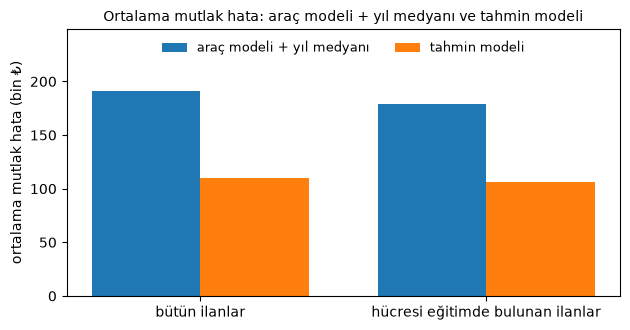

In [15]:
GROUPS_SHOWN = {"all": "bütün ilanlar", "own_cell": "hücresi eğitimde bulunan ilanlar"}
masks = {"all": np.ones(len(price), dtype=bool), "own_cell": own_cell}
positions = np.arange(len(masks))

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for i, (label, pred) in enumerate([("araç modeli + yıl medyanı", dealer_pred), ("tahmin modeli", base_price)]):
    mae = [np.abs(price - pred)[mask].mean() / 1e3 for mask in masks.values()]
    ax.bar(positions + (i - 0.5) * 0.38, mae, width=0.38, label=label)
ax.set_xticks(positions, [GROUPS_SHOWN[name] for name in masks])
ax.set_ylabel("ortalama mutlak hata (bin ₺)")
ax.set_ylim(0, 1.3 * np.abs(price - dealer_pred).mean() / 1e3)
ax.set_title("Ortalama mutlak hata: araç modeli + yıl medyanı ve tahmin modeli", fontsize=10)
ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper center")
fig.tight_layout()
plt.show()

**Ne görüyoruz.** İlanların çoğunun emsali var; emsalsiz ve ince hücredeki ilanlar küçük bir pay. Taban kendi
hücresini bulduğu ilanlarda da tahmin modelinin belirgin gerisinde: 2.1'deki fark merdivenin alt basamaklarından
gelmiyor. Aynı araç modeli ve aynı model yılı içinde de ilanlar kilometrede ve hasarda ayrılıyor; medyan bunları
görmüyor, tahmin modeli görüyor.

### 2.5 CatBoost

Tahmin modeli başka bir karar ağacı kütüphanesiyle, CatBoost'la, iki biçimde karşılaştırılıyor; katlar aynı:

- **CatBoost, aynı matrislerde** (`model.oof_catboost`): LightGBM'in kat matrisleri (1.2), kategorikler CatBoost'a
  kategorik olarak bildiriliyor. Girdi aynı olduğu için adil karşılaştırma bu.
- **CatBoost, kendi metin işleyişiyle** (`model.oof_catboost_native`): TF-IDF ve SVD yok; araç modeli ve seri adı ham
  metin olarak veriliyor, CatBoost onları kendisi sayıya çeviriyor.

İki CatBoost da aynı ayarla, sabit 500 turla eğitiliyor; erken durdurma yok. Ayarlar:

In [16]:
CB_NOTES = {"iterations": "ağaç sayısı (sabit)", "learning_rate": "her ağacın katkısı bu oranla küçültülür",
            "depth": "ağaç derinliği", "loss_function": "kare hata", "random_seed": "tohum",
            "verbose": "CatBoost'un kendi iletileri kapalı", "thread_count": "iş parçacığı sayısı",
            "allow_writing_files": "CatBoost eğitim günlüğü dosyası yazmasın"}

pd.DataFrame({"value": pd.Series(model.CB_PARAMS).astype(str), "note": pd.Series(CB_NOTES)}).rename_axis(
    "ayar").rename(columns={"value": "değer", "note": "ne"})

,değer,ne
ayar,,
iterations,500,ağaç sayısı (sabit)
learning_rate,0.06,her ağacın katkısı bu oranla küçültülür
depth,8,ağaç derinliği
loss_function,RMSE,kare hata
random_seed,42,tohum
verbose,0,CatBoost'un kendi iletileri kapalı
thread_count,16,iş parçacığı sayısı
allow_writing_files,False,CatBoost eğitim günlüğü dosyası yazmasın


İki kat dışı koşum, önbellekten; karşılaştırma tablosunda tabanlar ve tahmin modeli de var:

In [17]:
cb_svd = cache.load_or_run(model.oof_catboost, model_table, cv_folds)
cb_native = cache.load_or_run(model.oof_catboost_native, model_table, cv_folds)

VARIANT_TR.update({"catboost": "CatBoost, aynı matrislerde", "catboost_native": "CatBoost, kendi metin işleyişiyle"})
comparison = metric_table({"series_year": series_pred, "model_year": dealer_pred, "lightgbm": base_price,
                           "catboost": np.expm1(cb_svd), "catboost_native": np.expm1(cb_native)})
comparison.rename(index=VARIANT_TR, columns=METRIC_TR)

,MAE (₺),MedAE (₺),RMSE (₺),MAPE (%),R²
seri + yıl medyanı,203621,142500,308976,11.65,0.9216
araç modeli + yıl medyanı,191224,130000,305050,11.20,0.9235
tahmin modeli (LightGBM),109776,75320,176225,6.49,0.9745
"CatBoost, aynı matrislerde",110085,74927,176130,6.44,0.9745
"CatBoost, kendi metin işleyişiyle",112925,77660,178312,6.58,0.9739


**Ne görüyoruz.** LightGBM ile aynı matrislerdeki CatBoost pratikte eşit: fark küçük ve ölçüden ölçüye yön
değiştiriyor; R² dört haneye kadar aynı. Kendi metin işleyişiyle CatBoost ikisinin biraz gerisinde: bu veride ad
parçalarının TF-IDF + SVD'si, CatBoost'un araç modeli ve seri adını kendisinin sayıya çevirmesinden biraz daha çok
bilgi taşıyor. Karşılaştırma tam eşit koşullarda değil: LightGBM erken durduruluyor, CatBoost sabit turla eğitiliyor.
Bu defter ve sonrakiler boyunca tahmin modeli LightGBM; servis edilen de o (5. bölüm).

## 3. Marka ablasyonu

**Soru.** Seri ve araç modeli bilinince marka tahmin modeline bir şey katıyor mu? 2. defterde marka araç modelinden ve
seriden tamamen okunuyordu (Theil's U); burada aynı soru tahmin modelinin hatasıyla soruluyor.

Ablasyon: tahmin modeli yalnız kimlik kolonları değiştirilerek yeniden kuruluyor; öteki öznitelikler, katlar ve
ayarlar temel koşumla aynı. Üç kol:

- **yalnız marka**: araç modeli, seri ve segment çıkarılıyor. Segment de çıkıyor, çünkü seriden ve araç modeli adından
  türetiliyor (2. defter, 2. bölüm); kalsaydı seri bilgisinin bir kısmı içeride kalırdı.
- **seri + araç modeli**: marka çıkarılıyor.
- **marka + seri + araç modeli**: bütün öznitelikler, yani temel koşum; aynı kayıt okunuyor.

`model.oof_lightgbm`'in `drop` argümanı çıkarılan öznitelikler; bilinmeyen bir ad verilirse durur.

In [18]:
ARMS = {"brand_only": ["model", "series", "segment"], "series_model": ["brand"], "brand_series_model": []}
ARMS_TR = {"brand_only": "yalnız marka", "series_model": "seri + araç modeli",
           "brand_series_model": "marka + seri + araç modeli (temel koşum)"}

arms = {name: cache.load_or_run(model.oof_lightgbm, model_table, cv_folds, drop=drop) for name, drop in ARMS.items()}

arm_table = metric_table({name: np.expm1(run["pred_log"]) for name, run in arms.items()})
arm_table["trees"] = [" ".join(map(str, run["trees"])) for run in arms.values()]
arm_table.rename(index=ARMS_TR, columns={**METRIC_TR, "trees": "ağaç, kat kat"}).rename_axis("kol")

,MAE (₺),MedAE (₺),RMSE (₺),MAPE (%),R²,"ağaç, kat kat"
kol,,,,,,
yalnız marka,162812,99426,267224,8.80,0.9413,333 346 293 312 301
seri + araç modeli,109775,75320,176225,6.49,0.9745,274 258 212 212 307
marka + seri + araç modeli (temel koşum),109776,75320,176225,6.49,0.9745,274 258 212 212 307


**Ne görüyoruz.** Yalnız marka verilince hata belirgin büyüyor: aracın kimliği markadan değil, seriden ve araç
modelinden geliyor. Seri ve araç modelinin üzerine marka eklemek hatayı neredeyse hiç değiştirmiyor: yuvarlanmış
ölçülerde yalnız MAE'nin son hanesi oynuyor, erken durdurma da aynı turlarda duruyor. Bu bir ölçümden çok verinin
tanımı: her seri tek bir markaya ait (2. defter, 1.1), marka seriden okunabiliyor.

## 4. Hangi öznitelik ne kadar taşıyor

### 4.1 Bir öznitelik çıkınca: LOFO

**Soru.** Bir öznitelik (ya da bir öznitelik grubu) çıkarılıp tahmin modeli aynı katlar ve ayarlarla yeniden
kurulunca kat dışı hata ne kadar büyüyor? Bu yöntemin adı LOFO (leave one feature out). Ölçtüğü şey, o öznitelik
yokken geri kalanların telafi edemediği kısım; özniteliğin tahmin modelinde ne kadar kullanıldığı değil. Ana ölçü
RMSE farkı (₺), yanında MAPE farkı (puan); ikisi de "çıkarılmış eksi temel koşum", artı işaret hatanın büyüdüğü demek.

Çıkarılanlar sırasıyla: her sayısal öznitelik tek başına; grupların öteki üyeleri tek başına (tavan, kaput ve bagaj
durumu, araç modeli, seri); sonra üç grup bütün olarak. Bir grubu ve üyelerini ayrı ayrı çıkarmak, özniteliklerin
birbirinin yerini tutup tutmadığını gösterir. Altı kategorik öznitelik (marka, kasa tipi, çekiş, segment, vites,
yakıt) tek tek çıkarılmıyor (2026-09-25 kararı); markanın katkısı 3. bölümde.

In [19]:
GROUPS = {"engine": ["power_hp_val", "engine_cc_val"],
          "damage": ["roof_state", "hood_state", "trunk_state", "door_changed", "door_painted", "door_local",
                     "fender_changed", "fender_painted", "fender_local", "bumper_changed", "bumper_painted",
                     "bumper_local", "is_heavy_damaged"],
          "model_series": ["model", "series"]}

REMOVALS = {column: [column] for column in data.NUM}
for members in GROUPS.values():
    REMOVALS.update({column: [column] for column in members if column not in REMOVALS})
REMOVALS.update(GROUPS)
print(len(REMOVALS), "çıkarma:", len(REMOVALS) - len(GROUPS), "tek öznitelik,", len(GROUPS), "grup")

22 çıkarma: 19 tek öznitelik, 3 grup


Her çıkarma bir kat dışı koşum (`drop`), önbellekten:

In [20]:
lofo = {name: cache.load_or_run(model.oof_lightgbm, model_table, cv_folds, drop=drop)
        for name, drop in REMOVALS.items()}

lofo_rows = {}
for name, run in lofo.items():
    removed = model.price_metrics(price, np.expm1(run["pred_log"]))
    lofo_rows[name] = {"kind": "group" if name in GROUPS else "single",
                       "d_rmse": removed["rmse"] - base_metrics["rmse"],
                       "d_mape": removed["mape"] - base_metrics["mape"], "trees": " ".join(map(str, run["trees"]))}
lofo_table = pd.DataFrame(lofo_rows).T.sort_values("d_rmse", ascending=False)

damage_singles = lofo_table.loc[GROUPS["damage"], ["d_rmse", "d_mape"]].astype(float).sum()
print(f"Hasar kolonları tek tek çıkınca artışların toplamı: ΔRMSE {damage_singles['d_rmse']:,.0f} ₺, "
      f"ΔMAPE {damage_singles['d_mape']:.3f} puan")

Hasar kolonları tek tek çıkınca artışların toplamı: ΔRMSE 15,661 ₺, ΔMAPE 0.716 puan


Tablo büyükten küçüğe RMSE farkına göre; son kolon her katta erken durdurmanın seçtiği ağaç sayısı (temel koşumunki
1.4'te).

In [21]:
REMOVAL_TR = {"vehicle_age": "yaş", "gb_mileage": "km", "power_hp_val": "güç", "engine_cc_val": "hacim",
              "door_changed": "kapı değişen", "door_painted": "kapı boyalı", "door_local": "kapı lokal",
              "fender_changed": "çamurluk değişen", "fender_painted": "çamurluk boyalı",
              "fender_local": "çamurluk lokal", "bumper_changed": "tampon değişen", "bumper_painted": "tampon boyalı",
              "bumper_local": "tampon lokal", "is_heavy_damaged": "ağır hasar", "roof_state": "tavan durumu",
              "hood_state": "kaput durumu", "trunk_state": "bagaj durumu", "model": "araç modeli adı",
              "series": "seri adı", "engine": "motor grubu (güç + hacim)", "damage": "hasar grubu (13 kolon)",
              "model_series": "araç modeli + seri adı"}   # çıkarma kimliği -> gösterilen ad

shown = lofo_table.assign(d_rmse=lofo_table["d_rmse"].astype(float).round().astype(int),
                          d_mape=lofo_table["d_mape"].astype(float).round(3),
                          kind=lofo_table["kind"].map({"single": "tek", "group": "grup"}))
shown.rename(index=REMOVAL_TR, columns={"kind": "tür", "d_rmse": "ΔRMSE (₺)", "d_mape": "ΔMAPE (puan)",
                                        "trees": "ağaç, kat kat"}).rename_axis("çıkarılan")

,tür,ΔRMSE (₺),ΔMAPE (puan),"ağaç, kat kat"
çıkarılan,,,,
km,tek,54922,2.628,127 146 107 115 143
yaş,tek,46049,1.503,314 434 330 379 335
hasar grubu (13 kolon),grup,25473,1.241,117 118 133 112 154
araç modeli + seri adı,grup,19413,0.662,345 304 278 290 327
araç modeli adı,tek,15399,0.567,313 282 240 217 345
ağır hasar,tek,5207,0.260,195 242 205 215 219
kaput durumu,tek,2774,0.138,233 221 228 238 268
seri adı,tek,2071,0.033,259 228 235 176 248
çamurluk değişen,tek,1851,0.070,214 190 200 187 220


Grafik yalnız birbiriyle çakışmayan beş çıkarmayı çiziyor: km, yaş ve üç grup. Gruplar tek özniteliklerin de bir
kısmını içerdiği için hepsini aynı eksene koymak aynı bilgiyi iki kez saymak olurdu.

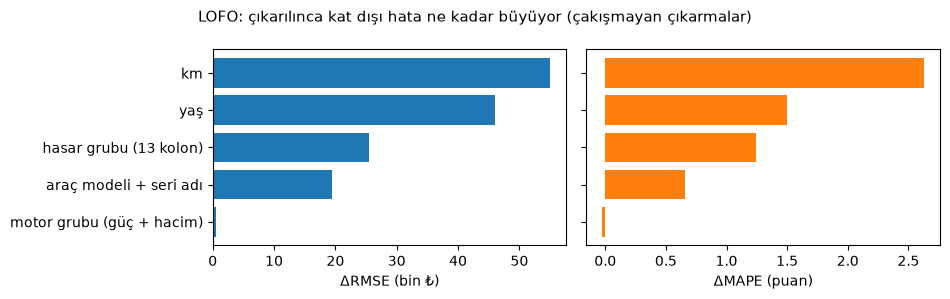

In [22]:
FLAT = ["gb_mileage", "vehicle_age", "damage", "model_series", "engine"]

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.0), sharey=True)
labels = [REMOVAL_TR[name] for name in FLAT]
axes[0].barh(labels, lofo_table.loc[FLAT, "d_rmse"].astype(float) / 1e3)
axes[1].barh(labels, lofo_table.loc[FLAT, "d_mape"].astype(float), color="tab:orange")
axes[0].set_xlabel("ΔRMSE (bin ₺)")
axes[1].set_xlabel("ΔMAPE (puan)")
axes[0].invert_yaxis()
fig.suptitle("LOFO: çıkarılınca kat dışı hata ne kadar büyüyor (çakışmayan çıkarmalar)", fontsize=11)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Km ve yaş çıkınca hata en çok büyüyor, iki ölçüde de: onların bilgisini başka hiçbir öznitelik
taşımıyor. Hasar grubu bütün olarak çıkınca hata, hasar kolonları tek tek çıkarıldığında görülen artışların
toplamından (tablodan önce yazdırılan satır) fazla büyüyor: hasar kolonları birbirinin yerini kısmen tutuyor (boyalı
kapı ile boyalı çamurluk gibi); tek başına en çok taşıyanı ağır hasar kaydı. Araç modeli adı tek başına çıkınca hata
belirgin büyüyor, seri adı tek başına çıkınca az: seri araç modelinin kaba hâli, araç modeli adı onu büyük ölçüde
telafi ediyor (2. defter, 1.1). İkisi birlikte çıkınca kayıp, tek tek kayıplarının toplamından büyük. Motor grubu
çıkınca RMSE çok az büyüyor, MAPE biraz düşüyor; güç tek başına çıkınca iki ölçüde de hata küçülüyor: motor bilgisi
büyük ölçüde araç modelinin adında. Tablonun alt yarısındaki küçük farklar 4.2'deki plaseboların farklarıyla aynı
büyüklükte; bunlar bilgi kaybından çok yeniden eğitimin oynaması gibi okunmalı.

### 4.2 Tahmin modelinde olmayan dört ham kolon: ekleme sınaması

**Soru.** Dört ham kolon tahmin modeline girmiyor: renk (`kb_color`), satıcı tipi (`kb_seller_type`), takas
(`kb_trade_available`) ve garanti (`gb_warranty_status`). 1. defterdeki eleme kurallarının hiçbirine uymuyorlar
(1. defter, 4.5); öznitelik listesi kurulurken hiç denenmemişlerdi. Eklenselerdi kat dışı hata değişir miydi?

Sınama LOFO'nun tersi (2026-11-25 kararı): her kolon temel koşumun bütün özniteliklerine tek başına eklenir; katlar,
ayarlar ve hata ölçüleri aynı. Eklenen kolon öteki kategorikler gibi kodlanır: kodlar eğitim kısmından, eğitimde
görülmemiş değer −1; boş değer kendi kategorisi (`missing`). Kolon matrisin en sonuna eklenir.

**Plasebo.** Her kolonun bir de karıştırılmış kopyası aynı biçimde eklenir: aynı değerler, ama ilanlara rastgele
dağıtılmış. Her kolon kendi permütasyonuyla karıştırılır (tohumu 42 olan tek üreteçten sırayla çekilir); böylece dört
plasebo birbirinden bağımsızdır. Kopya kolonun dağılımını korur, araçla ve fiyatla her bağını kaybeder. Plasebonun
gösterdiği şey, anlamsız bir kategorik kolon eklemenin kendisinin kat dışı hatayı ne kadar oynattığı. Bir varyant da
dört kolonu birlikte ekler.

In [23]:
SEED = 42
ADDED = ["kb_color", "kb_seller_type", "kb_trade_available", "gb_warranty_status"]
ADDED_TR = {"kb_color": "renk", "kb_seller_type": "satıcı tipi", "kb_trade_available": "takas",
            "gb_warranty_status": "garanti"}

extra = listings[ADDED].astype("string").fillna("missing")
rng = np.random.default_rng(SEED)
for column in ADDED:
    extra[f"{column}_shuffled"] = extra[column].to_numpy()[rng.permutation(len(listings))]
with_extra = model_table.join(extra)

pd.DataFrame({"n_values": extra[ADDED].nunique(), "missing_pct": 100 * (extra[ADDED] == "missing").mean()}).round(
    1).rename(index=ADDED_TR, columns={"n_values": "farklı değer (boş dahil)", "missing_pct": "boş (%)"})

,farklı değer (boş dahil),boş (%)
renk,24,0.0
satıcı tipi,3,0.0
takas,3,19.1
garanti,3,22.1


Varyantlar: her kolon, onun plasebosu ve dördü birlikte. `model.oof_lightgbm`'in `added` argümanı eklenen kolonlar;
tabloda olmayan ya da zaten öznitelik olan bir ad verilirse durur. Dokuz kat dışı koşum, önbellekten:

In [24]:
VARIANTS = {}
for column in ADDED:
    VARIANTS[column] = [column]
    VARIANTS[f"{column}_shuffled"] = [f"{column}_shuffled"]
VARIANTS["all_four"] = ADDED

added_runs = {name: cache.load_or_run(model.oof_lightgbm, with_extra, cv_folds, added=columns)
              for name, columns in VARIANTS.items()}
added_price = {name: np.expm1(run["pred_log"]) for name, run in added_runs.items()}

**Aralık.** Farkın belirsizliği eşli bootstrap ile: `model.paired_bootstrap` ilanları yerine koyarak 2.000 kez yeniden
çeker (tohum 42); her çekilişte temel koşumun ve her varyantın RMSE'si ve MAPE'si aynı ilanlarda hesaplanır ve fark
alınır. %95 aralık, bu 2.000 farkın 2,5 ve 97,5 yüzdelikleri. Eşli olması önemli: iki koşum aynı ilanlarda
karşılaştırıldığı için ilanların zorluğundan gelen değişkenlik farktan düşer. Önbellekten:

In [25]:
N_RESAMPLES = 2000
boot = cache.load_or_run(model.paired_bootstrap, price, base_price, added_price, n_resamples=N_RESAMPLES, seed=SEED)

add_rows = {}
for name, pred in added_price.items():
    metrics = model.price_metrics(price, pred)
    rmse_lo, rmse_hi = np.percentile(boot[name]["rmse"], [2.5, 97.5])
    mape_lo, mape_hi = np.percentile(boot[name]["mape"], [2.5, 97.5])
    add_rows[name] = {"rmse": metrics["rmse"], "mape": metrics["mape"],
                      "d_rmse": metrics["rmse"] - base_metrics["rmse"], "d_rmse_lo": rmse_lo, "d_rmse_hi": rmse_hi,
                      "d_mape": metrics["mape"] - base_metrics["mape"], "d_mape_lo": mape_lo, "d_mape_hi": mape_hi}
add_table = pd.DataFrame(add_rows).T

Tablo: her varyantın RMSE'si ve MAPE'si, temel koşuma göre farkları ve %95 aralıkları. ₺ tam sayıya, MAPE ve farkı üç
haneye yuvarlandı. Eksi fark hatanın düştüğü demek.

In [26]:
VARIANT_NAMES = {**{c: ADDED_TR[c] for c in ADDED}, **{f"{c}_shuffled": f"{ADDED_TR[c]}, plasebo" for c in ADDED},
                 "all_four": "dördü birlikte"}   # varyant kimliği -> gösterilen ad
TL_COLUMNS = ["rmse", "d_rmse", "d_rmse_lo", "d_rmse_hi"]
HEADER = {"rmse": ("RMSE (₺)", ""), "mape": ("MAPE (%)", ""), "d_rmse": ("ΔRMSE (₺)", "fark"),
          "d_rmse_lo": ("ΔRMSE (₺)", "alt"), "d_rmse_hi": ("ΔRMSE (₺)", "üst"), "d_mape": ("ΔMAPE (puan)", "fark"),
          "d_mape_lo": ("ΔMAPE (puan)", "alt"), "d_mape_hi": ("ΔMAPE (puan)", "üst")}

shown = add_table.round({**dict.fromkeys(TL_COLUMNS, 0), "mape": 3, "d_mape": 3, "d_mape_lo": 3, "d_mape_hi": 3})
shown = shown.astype(dict.fromkeys(TL_COLUMNS, int)).rename(index=VARIANT_NAMES).rename_axis("eklenen")
shown.set_axis(pd.MultiIndex.from_tuples([HEADER[c] for c in shown.columns]), axis=1)

RMSE (₺) MAPE (%) ΔRMSE (₺)            ΔMAPE (puan)  \
                                            fark  alt   üst         fark   
eklenen                                                                    
renk                   176146    6.449       -79 -826   609       -0.041   
renk, plasebo          177282    6.513      1057  532  1566        0.023   
satıcı tipi            176624    6.480       399 -164   931       -0.009   
satıcı tipi, plasebo   176457    6.502       232 -277   703        0.012   
takas                  176563    6.501       338 -227   911        0.011   
takas, plasebo         176794    6.507       569   59  1053        0.017   
garanti                176341    6.488       116 -407   659       -0.002   
garanti, plasebo       176707    6.506       482  -68  1013        0.016   
dördü birlikte         176370    6.450       145 -635   904       -0.040   

                                    
                        alt    üst  
eklenen                             
renk                 -0.059 -0.023  
renk, plasebo         0.010  0.036  
satıcı tipi          -0.023  0.004  
satıcı tipi, plasebo  0.000  0.024  
takas                -0.002  0.024  
takas, plasebo        0.005  0.028  
garanti              -0.014  0.011  
garanti, plasebo      0.004  0.028  
dördü birlikte       -0.060 -0.020

Aynı farklar kat kat: her katın kendi doğrulama ilanlarında varyantın hatası eksi temel koşumunki. Bootstrap ilanları
karıştırır, bu tablo katları ayrı tutar; bir farkın beş katın kaçında aynı yönde olduğu buradan okunur.

In [27]:
by_fold = {}
for name, pred in added_price.items():
    for k, (_, valid) in enumerate(cv_folds, 1):
        new, old = model.price_metrics(price[valid], pred[valid]), model.price_metrics(price[valid], base_price[valid])
        by_fold[name, k] = {"d_rmse": new["rmse"] - old["rmse"], "d_mape": new["mape"] - old["mape"]}
by_fold = pd.DataFrame(by_fold).T.unstack().reindex(list(VARIANTS))

pd.concat({"ΔRMSE (₺)": by_fold["d_rmse"].round().astype(int), "ΔMAPE (puan)": by_fold["d_mape"].round(3)},
          axis=1).rename(index=VARIANT_NAMES).rename_axis(index="eklenen", columns=[None, "kat"])

ΔRMSE (₺)                         ΔMAPE (puan)         \
kat                          1     2     3     4     5            1      2   
eklenen                                                                      
renk                      -146 -1017   522  1291 -1037       -0.024 -0.036   
renk, plasebo              392  1390   626  1833  1113        0.018  0.032   
satıcı tipi                 42   492  -206  1760     5       -0.008  0.012   
satıcı tipi, plasebo      -173   367  -494   891   637       -0.011  0.028   
takas                     -479  -591  1847   576   250        0.012  0.006   
takas, plasebo             -82   116   572  1386   884        0.013  0.015   
garanti                    413  -543   260   786  -329        0.008 -0.010   
garanti, plasebo          -717  1185   315   758   911        0.006  0.012   
dördü birlikte             680 -1314  1628   883 -1241       -0.015 -0.036   

                                           
kat                       3      4      5  
eklenen                                    
renk                 -0.059 -0.020 -0.064  
renk, plasebo         0.010  0.030  0.026  
satıcı tipi          -0.040  0.005 -0.017  
satıcı tipi, plasebo  0.012  0.020  0.011  
takas                 0.026  0.010  0.002  
takas, plasebo       -0.001  0.019  0.038  
garanti              -0.016  0.015 -0.005  
garanti, plasebo      0.001  0.038  0.023  
dördü birlikte       -0.049 -0.021 -0.077

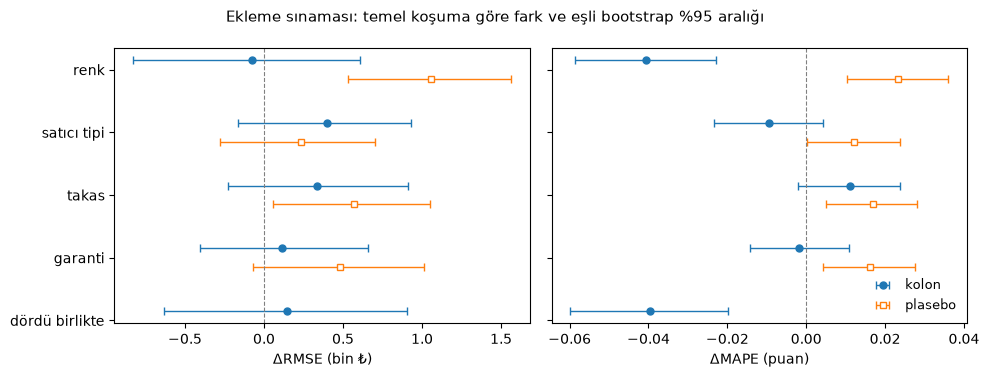

In [28]:
plotted = ADDED + ["all_four"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, measure, scale, unit in [(axes[0], "rmse", 1e3, "ΔRMSE (bin ₺)"), (axes[1], "mape", 1, "ΔMAPE (puan)")]:
    for offset, suffix, marker, label in [(-0.15, "", "o", "kolon"), (0.15, "_shuffled", "s", "plasebo")]:
        kept = [name for name in plotted if f"{name}{suffix}" in add_table.index]
        part = add_table.loc[[f"{name}{suffix}" for name in kept], [f"d_{measure}{end}" for end in ("", "_lo", "_hi")]]
        point, low_end, high_end = (part[column].to_numpy() / scale for column in part.columns)
        ax.errorbar(point, [plotted.index(name) + offset for name in kept], xerr=[point - low_end, high_end - point],
                    fmt=marker, ms=5, capsize=3, lw=1, label=label, mfc="white" if suffix else None)
    ax.axvline(0, color="grey", ls="--", lw=0.8)
    ax.set_xlabel(unit)
axes[0].set_yticks(range(len(plotted)), [VARIANT_NAMES[name] for name in plotted])
axes[0].invert_yaxis()
axes[1].legend(frameon=False, fontsize=9)
fig.suptitle("Ekleme sınaması: temel koşuma göre fark ve eşli bootstrap %95 aralığı", fontsize=11)
fig.tight_layout()
plt.show()

**Ne gösterebilir, ne gösteremez.**

- **Tek tohum, katta tek eğitim.** Her varyant her katta bir kez, tohum 42 ile eğitiliyor. İki koşumun farkı yalnız
  eklenen kolonun bilgisi değil: kolon eklenince ağaçlar başka bölünmelerle büyüyor, erken durdurma başka bir turda
  duruyor. Plasebo bu oynamanın bilgisi olmayan bir kolonda ne kadar olduğunu gösteriyor; bir kolonun farkı ancak
  plasebosununkiyle yan yana okunur.
- **Bootstrap aralığı neyi kapsıyor.** Aralık, eğitilmiş tahmin modelleri sabitken ilanların örneklenmesinden gelen
  belirsizlik: aynı türden başka ilanlarda fark ne kadar oynardı. Tahmin modelini yeniden kurmaktan (başka bir tohum,
  başka katlar) gelen belirsizliği kapsamıyor. Kat kat farklar bunun kaba bir göstergesi.
- **Karar.** Sonuç ne çıkarsa çıksın bu kolonlar tahmin modeline eklenmiyor; servis edilen tahmin modeli olduğu gibi
  kalıyor. Sınama yalnız neyin dışarıda kaldığını ve bunun ne kadara mal olduğunu kaydediyor.

**Ne görüyoruz.**

- **Plasebolar** hatayı büyütüyor: dördünün de noktası iki ölçüde artıda; aralıkların MAPE'de çoğu, RMSE'de bir
  kısmı sıfırın üstünde. Bilgisi olmayan bir kategorik kolon tahmin modeline gürültü katıyor ve bunun küçük bir
  bedeli var.
- **Renk** MAPE'yi düşürüyor: aralık sıfırın altında, düşüş beş katın beşinde, plasebosu ise ters yönde. RMSE'de
  ölçülebilir bir değişiklik yok: aralık sıfırı içeriyor, katlar iki yöne dağılıyor. Renk yüzde hatayı biraz
  küçültüyor, büyük ₺ hatalarını (RMSE'yi belirleyenler) değiştirmiyor. Kazanç temel koşumun hatasının yanında küçük.
- **Satıcı tipi, takas ve garanti**: farkın aralığı iki ölçüde de sıfırı içeriyor; bu sınamada kat dışı hatayı
  ölçülebilir biçimde değiştirmiyorlar. Takasın MAPE farkı her katta, küçük de olsa, artıda. Bir kolonla plasebosunun
  farkı burada ayrıca sınanmadı.
- **Dördü birlikte** eklenince sonuç yalnız rengin eklendiği hâle çok yakın.

Karar değişmiyor: dört kolon da tahmin modeline eklenmiyor. Renk küçük ama ölçülebilir bir katkı veriyor; karşılığında
servis edilen tahmin modelinden ayrılmak gerekirdi.

## 5. Son tahmin modeli

**Soru.** Servis edilen tahmin modeli nasıl eğitiliyor?

Son tahmin modeli bütün ilanlarla eğitiliyor. Matris bir katınkiyle aynı biçimde kuruluyor, yalnız kategori kodları ve
TF-IDF + SVD bütün ilanlardan öğreniliyor. Ayarlar aynı; tek fark ağaç sayısı. Bütün ilanlar eğitimde olduğu için
erken durdurmanın bakacağı bir doğrulama kısmı yok; ağaç sayısı, 1.4'teki beş katta erken durdurmanın seçtiği ağaç
sayılarının medyanı. Böylece servis edilen tahmin modeli, hatası ölçülen ayarla eğitilmiş oluyor. `model.fit_final`
bunu yapar; önbellekten:

In [29]:
final_trees = int(np.median(base["trees"]))
final = cache.load_or_run(model.fit_final, model_table, final_trees)
print("Katların ağaç sayısı:", base["trees"], "| medyan:", final_trees)
print("Son tahmin modeli:", final.booster_.num_trees(), "ağaç; matris (satır, kolon):", (len(model_table),
                                                                                        final.n_features_in_))

column_kinds(final.feature_name_, categorical).rename(KIND_TR).rename_axis("kolon türü").rename("kolon").to_frame()

Katların ağaç sayısı: [274, 258, 212, 212, 307] | medyan: 258
Son tahmin modeli: 258 ağaç; matris (satır, kolon): (29988, 193)


,kolon
kolon türü,
kategorik,9
sayısal,14
araç modeli adı (SVD),150
seri adı (SVD),20


**Ne görüyoruz.** Son tahmin modeli katların seçtiği ağaç sayılarının ortadakiyle eğitildi. Matrisi bir katın
matrisiyle aynı kolonlardan oluşuyor (1.2): aynı kategorik ve sayısal kolonlar, araç modeli ve seri adının aynı sayıda
SVD kolonu; yalnız kodlar ve SVD bütün ilanlardan öğrenildi.

Bu tahmin modelini servis dosyasına yazmak bu defterin işi değil, dışa aktarım aşamasının; bu defter hiçbir servis
dosyası yazmaz. Aynı ilanlarla eğitilen iki CatBoost da dışa aktarım aşamasına bırakıldı. Aracın tahmin aralığı,
isabet olasılığı ve emsal tablosu 4. defterde.

## Özet

- **Tahmin modeli (1):** LightGBM, log fiyat üzerinde, ortak beş katta. Kategorik kodlar ve araç modeli ile seri
  adının TF-IDF + SVD'si her katta yalnız eğitim kısmından kuruluyor; ağaçlar erken durdurmayla. Kat dışı hata
  tipik ilanda küçük; birkaç büyük hata RMSE'yi büyütüyor.
- **Tabanlar ve karşılaştırma (2):** araç modeli + yıl medyanı tahmin modelinin çok gerisinde, kendi hücresini bulduğu
  ilanlarda da; emsal yoksa taban çöküyor. Aynı matrislerdeki CatBoost pratikte eşit, kendi metin işleyişiyle biraz
  geride.
- **Marka (3):** seri ve araç modeli bilinince marka bir şey katmıyor; yalnız marka çok daha kötü.
- **LOFO (4.1):** en çok km ve yaş taşıyor, sonra hasar grubu ve araç modelinin adı. Hasar kolonları birbirinin
  yerini kısmen tutuyor; motor bilgisi büyük ölçüde araç modelinin adında.
- **Dört ham kolon (4.2):** renk MAPE'yi biraz düşürüyor, RMSE'yi değiştirmiyor; satıcı tipi, takas ve garanti
  ölçülebilir bir şey katmıyor; bilgisiz bir kolon eklemek hatayı biraz büyütüyor. Kolonlar tahmin modeline
  eklenmiyor.
- **Son tahmin modeli (5):** bütün ilanlarla, katlarda seçilen ağaç sayılarının medyanıyla, erken durdurmasız.

## Başlık sayıları

Defterin sayıları tek tabloda, her biri hesaplandığı bölümle. Tablo iki iş görüyor: sonuçları bir arada gösteriyor ve
defter yeniden çalıştırıldığında sayıların değişip değişmediği bu tablodan denetleniyor; bu yüzden kısa tutulmadı.
Anahtarlar kod adı olduğu için İngilizce; sayılar yukarıdaki tablolardaki gibi yuvarlandı. ₺ sayıları tam ₺, MAPE
iki, MAPE farkları üç hane.

In [30]:
rows = [
    ("lightgbm_mae", int(comparison.loc["lightgbm", "mae"]), "tahmin modeli: MAE (₺)", "1.4"),
    ("lightgbm_rmse", int(comparison.loc["lightgbm", "rmse"]), "tahmin modeli: RMSE (₺)", "1.4"),
    ("lightgbm_mape", float(comparison.loc["lightgbm", "mape"]), "tahmin modeli: MAPE (%)", "1.4"),
    ("lightgbm_r2", float(comparison.loc["lightgbm", "r2"]), "tahmin modeli: R²", "1.4"),
    ("cv_trees", " ".join(map(str, base["trees"])), "erken durdurmanın seçtiği ağaç, kat kat", "1.4"),
    ("series_year_mape", float(comparison.loc["series_year", "mape"]), "seri + yıl medyanı: MAPE (%)", "2.1"),
    ("model_year_mae", int(comparison.loc["model_year", "mae"]), "araç modeli + yıl medyanı: MAE (₺)", "2.1"),
    ("model_year_mape", float(comparison.loc["model_year", "mape"]), "araç modeli + yıl medyanı: MAPE (%)", "2.1"),
    ("comparable_cells", n_cells, "(araç modeli, model yılı) hücresi", "2.3"),
    ("no_comparable_pct", float(round(coverage["singleton_pct"], 2)), "emsalsiz ilan (%)", "2.3"),
    ("ladder_fallback_pct", float(round(coverage["fallback_pct"], 2)), "merdivenin indiği ilan (%)", "2.3"),
    ("same_listing_improvement_pct", float(round(same["improvement_pct"], 1)),
     "hücresi bulunan ilanlarda tahmin modelinin tabana göre MAE iyileşmesi (%)", "2.4"),
    ("catboost_mape", float(comparison.loc["catboost", "mape"]), "CatBoost, aynı matrislerde: MAPE (%)", "2.5"),
    ("catboost_native_mape", float(comparison.loc["catboost_native", "mape"]),
     "CatBoost, kendi metin işleyişiyle: MAPE (%)", "2.5"),
    ("brand_only_mae", int(arm_table.loc["brand_only", "mae"]), "yalnız marka: MAE (₺)", "3"),
    ("brand_only_mape", float(arm_table.loc["brand_only", "mape"]), "yalnız marka: MAPE (%)", "3"),
    ("series_model_mae", int(arm_table.loc["series_model", "mae"]), "seri + araç modeli: MAE (₺)", "3"),
]
rows += [(f"lofo_d_rmse_{name}", int(round(float(lofo_table.loc[name, "d_rmse"]))),
          f"LOFO, {REMOVAL_TR[name]} çıkınca: ΔRMSE (₺)", "4.1") for name in FLAT]
for name in VARIANTS:
    if not name.endswith("_shuffled"):
        rows.append((f"add_{name}_d_rmse", int(round(add_table.loc[name, "d_rmse"])),
                     f"{VARIANT_NAMES[name]} eklenince: ΔRMSE (₺)", "4.2"))
    rows.append((f"add_{name}_d_mape", float(round(add_table.loc[name, "d_mape"], 3)),
                 f"{VARIANT_NAMES[name]} eklenince: ΔMAPE (puan)", "4.2"))
rows += [
    ("final_trees", final_trees, "son tahmin modelinin ağaç sayısı", "5"),
]
headline = {key: value for key, value, _, _ in rows}

headline_table = pd.DataFrame(rows, columns=["key", "value", "description", "section"], dtype=object).set_index("key")
headline_table[["value", "section", "description"]].rename_axis("anahtar").rename(
    columns={"value": "değer", "section": "bölüm", "description": "ne"})

,değer,bölüm,ne
anahtar,,,
lightgbm_mae,109776,1.4,tahmin modeli: MAE (₺)
lightgbm_rmse,176225,1.4,tahmin modeli: RMSE (₺)
lightgbm_mape,6.49,1.4,tahmin modeli: MAPE (%)
lightgbm_r2,0.9745,1.4,tahmin modeli: R²
cv_trees,274 258 212 212 307,1.4,"erken durdurmanın seçtiği ağaç, kat kat"
series_year_mape,11.65,2.1,seri + yıl medyanı: MAPE (%)
model_year_mae,191224,2.1,araç modeli + yıl medyanı: MAE (₺)
model_year_mape,11.2,2.1,araç modeli + yıl medyanı: MAPE (%)
comparable_cells,2194,2.3,"(araç modeli, model yılı) hücresi"
